# Обучение с учителем, без учителя и с подкреплением

Способ обучения определяется тем, **какую обратную связь получает система**. При обучении с учителем доступны примеры с нужными ответами. При обучении без учителя ответы к объектам не передаются: система ищет структуру входных данных. При обучении с подкреплением агент действует в среде и получает награды за последствия действий.

В материале используются готовые небольшие таблицы и простая учебная среда. Все примеры выполнены, результаты и рисунки сохранены. Перед каждым блоком кода описана его цель, после результата разобраны команды и конструкции Python, включая базовые. Заданий и математической теории нет.

Ноутбук самодостаточен: данные создаются внутри файла, внешние модели и наборы данных не загружаются. Для повторного выполнения нужна среда Python с NumPy, Pandas, Matplotlib и scikit-learn. Ячейки выполняются сверху вниз в одном ядре.

**Содержание**

- [1. Что является обучающим сигналом](#signals)
- [2. Обучение с учителем: примеры и ответы](#supervised)
- [3. Обучение без учителя: структура без готовых ответов](#unsupervised)
- [4. Обучение с подкреплением: действия и последствия](#reinforcement)
- [5. Сопоставление трёх способов](#comparison)

<a id="signals"></a>
## 1. Что является обучающим сигналом

### 1.1. Различие в постановке задачи

| Способ | Что получает система | Какой сигнал помогает обучаться | Что получается в наших примерах |
|---|---|---|---|
| С учителем | описания объектов и известные ответы | ответ для каждого учебного объекта | модель решения по заявке и модель времени обработки |
| Без учителя | описания объектов без целевого ответа | структура самих данных, определяемая выбранным методом | группы похожих по составу заявок |
| С подкреплением | состояние среды и возможность действовать | награды после действий и развития ситуации | правило выбора двери в каждом состоянии |

«Учитель» — название роли готового ответа в данных. Для обучения не требуется, чтобы человек присутствовал рядом при каждом вызове программы. Ответы могли быть подготовлены заранее разметчиками, специалистами или надёжным процессом регистрации результата.

«Без учителя» не означает отсутствие решений разработчика: он по-прежнему выбирает входные поля, метод и его настройки. «Подкрепление» не означает готовую подсказку правильного действия: награда оценивает последствия, а выбор действий нужно освоить.

### 1.2. Обучение и применение

**Обучение** изменяет модель или правило действий по доступному сигналу. **Применение** использует уже полученный результат. При обычном вызове предсказания модель scikit-learn в этом примере не учится заново на новых строках.

Тип модели и способ обучения — разные понятия. Например, нейронная сеть описывает устройство модели, а наличие меток или наград — организацию обучения. Один проект может сочетать несколько способов на разных этапах.

Первый блок подключает средства работы с таблицами, массивами и рисунками, а также готовые учебные модели. Все модели будут обучаться на маленьких данных внутри ноутбука. В выводе фиксируется установленная версия scikit-learn.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.cluster import AgglomerativeClustering
from IPython.display import display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.constrained_layout.use'] = True

print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.8.0


**Разбор кода.**

- `%matplotlib inline` — команда Jupyter, включающая показ рисунков под ячейками. Начальный `%` здесь относится к среде ноутбука.
- `import` подключает установленные библиотеки. Части `as np`, `as pd`, `as plt` дают им короткие имена. Точка в `matplotlib.pyplot` выбирает часть библиотеки для рисования.
- `from sklearn.tree import ...` подключает два отдельных класса готовых моделей. `DecisionTreeClassifier` возвращает категории, `DecisionTreeRegressor` — числовой ответ. Запятая разделяет два подключаемых имени.
- `from sklearn.cluster import AgglomerativeClustering` подключает готовый метод группировки. Здесь он нужен для примера без целевых меток; устройство его алгоритма не требуется для чтения интерфейса примера.
- В имени устанавливаемой библиотеки используется `scikit-learn`, а в коде — `sklearn`. Это принятые разные названия одного программного пакета.
- `from IPython.display import display` подключает функцию оформленного показа таблиц. **Функция** выполняет действие при вызове; вызов записывается с круглыми скобками.
- `plt.rcParams['font.family'] = ...` выбирает настройку по текстовому ключу и присваивает ей шрифт. `True` во второй настройке включает автоматическое размещение элементов рисунка. Текст в кавычках — строка; один знак `=` — присваивание.
- `sklearn.__version__` — атрибут с версией. Подчёркивания являются частью его имени. Атрибут читается без скобок, а `print(...)` вызывается со скобками и выводит подпись и значение через пробел.

Подключение делает классы доступными, но ещё не создаёт и не обучает конкретные модели. Имена библиотек остаются в памяти ядра для следующих ячеек.

<a id="supervised"></a>
## 2. Обучение с учителем: примеры и ответы

### 2.1. Объект, признаки и целевой ответ

**Объект** — одна заявка. **Признаки** — её входное описание, доступное до решения: количество текстовых файлов и изображений. **Целевой ответ** — то, что модель должна научиться возвращать. В первом примере это решение специалиста: «Автоматически» или «Ручная проверка».

Метки в учебной таблице заданы заранее. Они передают выбранную политику обработки заявок, а не универсальное свойство текстов и изображений. Второй известный результат, время обработки, пригодится для отдельной задачи с числовым ответом.

Входные поля отделяются от ответов: модель должна научиться получать ответ **из описания**, а не читать готовый ответ среди входных столбцов.

Следующий блок создаёт двенадцать учебных заявок. Для каждой записаны два входных количества, известное решение и зарегистрированное время обработки. Таблица вымышленная и уже подготовлена к примерам; каждый кортеж описывает одну заявку.

In [2]:
request_rows = [
    ('R001', 6, 0, 'Автоматически', 3.0),
    ('R002', 7, 1, 'Автоматически', 4.0),
    ('R003', 8, 0, 'Автоматически', 4.0),
    ('R004', 7, 0, 'Автоматически', 3.0),
    ('R005', 0, 6, 'Автоматически', 7.0),
    ('R006', 1, 7, 'Автоматически', 8.0),
    ('R007', 0, 8, 'Автоматически', 9.0),
    ('R008', 1, 6, 'Автоматически', 7.0),
    ('R009', 4, 4, 'Ручная проверка', 8.0),
    ('R010', 3, 4, 'Ручная проверка', 8.0),
    ('R011', 4, 3, 'Ручная проверка', 9.0),
    ('R012', 5, 4, 'Ручная проверка', 9.0),
]
requests = pd.DataFrame(request_rows, columns=[
    'request_id', 'text_files', 'image_files', 'decision', 'elapsed_seconds',
])
display(requests)

,request_id,text_files,image_files,decision,elapsed_seconds
0,R001,6,0,Автоматически,3.0
1,R002,7,1,Автоматически,4.0
2,R003,8,0,Автоматически,4.0
3,R004,7,0,Автоматически,3.0
4,R005,0,6,Автоматически,7.0
5,R006,1,7,Автоматически,8.0
6,R007,0,8,Автоматически,9.0
7,R008,1,6,Автоматически,7.0
8,R009,4,4,Ручная проверка,8.0
9,R010,3,4,Ручная проверка,8.0


**Разбор кода.**

- `request_rows = [...]` сохраняет список записей в переменную. Переменная — имя для значения. Квадратные скобки создают список, запятые разделяют его элементы.
- Каждый внутренний набор `(...)` — кортеж, то есть упорядоченная группа значений. Порядок одинаков: идентификатор, текстовые файлы, изображения, решение, время.
- `'R001'` и `'Автоматически'` — строки в кавычках. `6`, `0` — целые числа, `3.0` — дробное число с точкой в записи Python. Ведущий `R` в идентификаторе — часть текста.
- `pd.DataFrame(request_rows, columns=[...])` создаёт таблицу. `DataFrame` — класс, вид объектов; его вызов создаёт конкретный экземпляр. Первый аргумент — данные, именованный аргумент `columns` — список имён полей.
- Имена `text_files`, `image_files` обозначают количества двух видов файлов, `decision` — решение, `elapsed_seconds` — время в секундах. Подчёркивания соединяют слова без пробелов.
- Переносы внутри незакрытых скобок продолжают один вызов. Последняя запятая в списке допустима. `display(requests)` показывает все двенадцать строк с индексом Pandas слева.

Наличие ответов в таблице ещё не означает, что обучение произошло. Следующие ячейки явно выбирают входы и передают ответы модели отдельным аргументом.

Этот блок отделяет два входных столбца от известного решения. В выводе первые четыре описания и ответы показаны раздельно: так видно, что идентификатор, решение и уже измеренное время не входят в описание для классификации.

In [3]:
feature_columns = ['text_files', 'image_files']
training_features = requests.loc[:, feature_columns]
training_labels = requests['decision']

display(training_features.head(4))
display(training_labels.head(4))
print('Форма входов:', training_features.shape)
print('Форма ответов:', training_labels.shape)

,text_files,image_files
0,6,0
1,7,1
2,8,0
3,7,0


0    Автоматически
1    Автоматически
2    Автоматически
3    Автоматически
Name: decision, dtype: object

Форма входов: (12, 2)
Форма ответов: (12,)


**Разбор кода.**

- `feature_columns = [...]` создаёт список двух имён. Именно этот список определяет, что доступно модели на входе. Один знак `=` сохраняет значение, а не сравнивает объекты.
- `requests.loc[:, feature_columns]` выбирает все строки через `:` и нужные столбцы через список после запятой. `loc` использует квадратные скобки как интерфейс выбора, а не круглые скобки вызова.
- `requests['decision']` выбирает один столбец как Series. Здесь квадратные скобки после имени означают выбор, а не создание нового списка. В результате описания хранятся в DataFrame, ответы — в Series.
- `.head(4)` возвращает первые четыре элемента или строки для просмотра. Вложенный вызов выполняется до `display(...)`, показывающего результат.
- `.shape` — атрибут формы. `(12, 2)` сообщает двенадцать объектов и два входа, `(12,)` — одномерный набор из двенадцати ответов. Запятая в `(12,)` показывает кортеж из одного числа.
- `print(...)` выводит подпись и форму через пробел. Названия `training_features`, `training_labels` помогают отличить входы от меток, но сами не обучают модель.

Порядок строк у входов и ответов совпадает: первый ответ относится к первому описанию. Наличие правильного столбца мало, если потерять соответствие объектов ответам.

### 2.2. Классификация: ответ является категорией

**Классификация** возвращает один из известных классов, в нашем случае вариант решения по заявке. Класс может быть записан текстом или числовым кодом; числовая запись сама по себе не превращает задачу в прогноз количества.

У готового объекта модели есть настройки, заданные разработчиком, и результат обучения, полученный из данных. Метод обучения получает и описания, и метки. Самостоятельно придумывать правила выбора класса в коде примера не требуется: они определяются при обучении.

Следующий блок создаёт классификатор и обучает его по двум входам и известным решениям. После обучения выводятся распознанные названия классов и число входных полей; это сведения о конкретном обученном объекте.

In [4]:
classifier = DecisionTreeClassifier(max_depth=2, random_state=42)
classifier.fit(training_features, training_labels)

print('Классы после обучения:', classifier.classes_)
print('Число входных полей:', classifier.n_features_in_)

Классы после обучения: ['Автоматически' 'Ручная проверка']
Число входных полей: 2


**Разбор кода.**

- `DecisionTreeClassifier(...)` создаёт готовую модель классификации. Имя класса подключено в первой ячейке. Переменная `classifier` сохраняет объект для обучения и дальнейшего применения.
- `max_depth=2` ограничивает число уровней решений в выбранной реализации модели. `random_state=42` фиксирует начальное состояние используемой ею случайности для воспроизводимости в данной среде. Это настройки до обучения, а не ответы по объектам.
- `.fit(training_features, training_labels)` — вызов обучения. Первый аргумент содержит входные строки, второй — известные классы в соответствующем порядке. Метод изменяет обучаемое состояние `classifier`; его результат не нужно присваивать второй раз.
- `.classes_` — атрибут с названиями классов, известными после обучения. `.n_features_in_` — число входных полей. Конечное подчёркивание в этих именах является частью интерфейса scikit-learn и часто обозначает сведения, появившиеся при обучении.
- Атрибуты читаются через точку без скобок. `print(...)` получает подпись и значение атрибута и выводит их в одной строке.

Вызов `fit` использовал разметку, но объект модели не становится источником подтверждённых ответов для всех будущих заявок. Его новые результаты являются предсказаниями.

Этот блок создаёт три новые заявки и передаёт классификатору только их входное описание. Предсказанные решения добавляются к копии таблицы для просмотра. Разметка новых заявок не задаётся и не передаётся в вызов предсказания.

In [5]:
new_requests = pd.DataFrame({
    'request_id': ['N001', 'N002', 'N003'],
    'text_files': [9, 1, 4],
    'image_files': [1, 9, 5],
})
predicted_labels = classifier.predict(new_requests.loc[:, feature_columns])
classification_result = new_requests.copy()
classification_result['predicted_decision'] = predicted_labels
display(classification_result)

,request_id,text_files,image_files,predicted_decision
0,N001,9,1,Автоматически
1,N002,1,9,Автоматически
2,N003,4,5,Ручная проверка


**Разбор кода.**

- `pd.DataFrame({...})` создаёт таблицу из словаря. В каждой паре ключ перед двоеточием — имя столбца, список после двоеточия — его значения. Элементы с одинаковым номером образуют одну новую заявку.
- `.loc[:, feature_columns]` выбирает те же два входа в том же порядке, что использовались при обучении. Идентификатор остаётся полезным для вывода, но не становится входом модели.
- `classifier.predict(...)` применяет уже обученный классификатор. Метод получает только описания: отдельный аргумент с ответами здесь отсутствует. Результат — массив предсказанных классов в порядке переданных строк.
- `new_requests.copy()` создаёт отдельную таблицу для показа. Присваивание `classification_result['predicted_decision'] = ...` добавляет в неё столбец результата.
- Имя `predicted_decision` означает «предсказанное решение» и специально отличает результат модели от известной разметки `decision`. Текстовое имя поля не меняет его статус на подтверждённый ответ.
- `display(...)` показывает три заявки вместе с результатами. Код не содержит нового вызова `.fit`, поэтому эта ячейка не переобучает классификатор.

По трём показанным ответам нельзя заключить, что модель надёжна для реального сервиса. Здесь проверяется понятная последовательность: известные примеры — обучение — применение к новым входам.

### 2.3. Регрессия: ответ является числовой величиной

**Регрессия** нужна, когда требуется получить величину, например время обработки в секундах. Это тоже обучение с учителем: у учебных объектов есть известные числовые ответы.

У одного набора описаний могут быть разные целевые поля для разных задач. Решение «Ручная проверка» и число секунд — два разных ответа; для них создаются отдельные модели. Прогноз времени не означает, что заявка уже была обработана за это время.

Следующий блок обучает отдельную модель по известному времени тех же двенадцати заявок. Затем она прогнозирует время для трёх новых входов. В выводе числовой результат явно назван прогнозом и указан в секундах.

In [6]:
regressor = DecisionTreeRegressor(max_depth=2, random_state=42)
regressor.fit(training_features, requests['elapsed_seconds'])

predicted_seconds = regressor.predict(new_requests.loc[:, feature_columns])
time_result = new_requests.copy()
time_result['predicted_seconds'] = predicted_seconds.round(2)
display(time_result)

,request_id,text_files,image_files,predicted_seconds
0,N001,9,1,4.00
1,N002,1,9,7.80
2,N003,4,5,8.67


**Разбор кода.**

- `DecisionTreeRegressor(...)` создаёт отдельный объект модели с числовым ответом. Настройки `max_depth` и `random_state` передаются по именам. Он не заменяет уже созданный `classifier`.
- `.fit(training_features, requests['elapsed_seconds'])` получает прежние входы, но другой целевой столбец. Выбор через `['elapsed_seconds']` возвращает Series известных времён.
- `.predict(...)` применяет обученный `regressor` к новым входам. Возвращается числовой массив `predicted_seconds`, а не массив названий классов.
- Метод массива `.round(2)` возвращает значения, округлённые до двух знаков после точки для показа. Он не обучает модель повторно и не делает прогноз точнее.
- `.copy()` создаёт таблицу результата. Присваивание нового столбца сохраняет прогноз рядом с исходными признаками; `display(...)` показывает всю таблицу.

Два примера различаются смыслом целевого ответа. Наличие чисел среди входных полей было одинаковым и само по себе не определяло, классификация это или регрессия.

<a id="unsupervised"></a>
## 3. Обучение без учителя: структура без готовых ответов

### 3.1. Что передаётся при обучении

**Кластеризация** объединяет объекты в группы по их входному описанию. Название группы и её деловой смысл заранее не заданы как правильный ответ для каждой строки. Результат зависит от входных данных, выбранного метода и настроек.

Для сопоставимости берутся те же двенадцать заявок, но их решения не передаются методу группировки. Наличие меток в соседней переменной не делает обучение автоматически обучением с учителем: важен фактический вход обучающего вызова.

В наших входах оба поля обозначают количества файлов. Здесь достаточно сравнить получившиеся группы по этим двум понятным осям.

Следующий блок подготавливает таблицу только с двумя входными полями для группировки. В ней нет решения специалиста и времени обработки. Вывод позволяет проверить состав передаваемых данных до создания групп.

In [7]:
unlabelled_features = requests.loc[:, feature_columns].copy()
display(unlabelled_features)
print('Поля для группировки:', unlabelled_features.columns.tolist())

,text_files,image_files
0,6,0
1,7,1
2,8,0
3,7,0
4,0,6
5,1,7
6,0,8
7,1,6
8,4,4
9,3,4


Поля для группировки: ['text_files', 'image_files']


**Разбор кода.**

- `requests.loc[:, feature_columns]` выбирает все строки и два ранее названных входных поля. Знак `:` относится к строкам, список после запятой — к столбцам.
- Метод `.copy()` создаёт отдельную рабочую таблицу. Имя `unlabelled_features` означает описания без целевых меток; важен именно выбранный состав полей, а не английское имя переменной.
- `display(...)` показывает все входы. `unlabelled_features.columns` получает объект имён столбцов, `.tolist()` превращает его в обычный список.
- `print(...)` выводит список рядом с подписью. Один знак `=` в первой строке присваивает результат переменной и не запускает обучение.

Эта таблица пригодна и для другой постановки задачи с теми же входами. Целевой ответ определял бы задачу только при его отдельной передаче в обучение.

### 3.2. Группа появляется в результате работы метода

В примере заранее запрашиваются **три группы**. Их количество — настройка разработчика, а не автоматически обнаруженный факт о предметной области. Число групп отличается от двух классов решения специалиста в предыдущем примере.

Номер группы — техническая метка. Он не означает качество, приоритет, сложность или готовое бизнес-название. Перестановка таких номеров не меняет сам состав групп.

Этот блок запускает группировку по двум входам и добавляет полученные номера к заявкам. Обучающий вызов получает только описания. Метод одновременно строит разбиение переданной партии и возвращает принадлежность каждой её строки к группе.

In [8]:
cluster_model = AgglomerativeClustering(n_clusters=3)
cluster_labels = cluster_model.fit_predict(unlabelled_features)

clustered_requests = requests.loc[:, ['request_id'] + feature_columns].copy()
clustered_requests['group_id'] = cluster_labels
display(clustered_requests)

,request_id,text_files,image_files,group_id
0,R001,6,0,2
1,R002,7,1,2
2,R003,8,0,2
3,R004,7,0,2
4,R005,0,6,0
5,R006,1,7,0
6,R007,0,8,0
7,R008,1,6,0
8,R009,4,4,1
9,R010,3,4,1


**Разбор кода.**

- `AgglomerativeClustering(n_clusters=3)` создаёт готовый объект группировки. `n_clusters` — имя настройки количества групп, `3` — её значение. Кавычки вокруг числа не нужны.
- `.fit_predict(unlabelled_features)` обучается на переданной таблице и возвращает номера групп этих же объектов. Отдельный аргумент с целевыми ответами отсутствует.
- Этот вызов относится к переданной партии. `fit_predict` здесь не является обещанием метода назначения группы произвольной новой строке после обучения.
- В `['request_id'] + feature_columns` оператор `+` соединяет два обычных списка имён в один. Это отличается от поэлементных числовых действий над массивом NumPy.
- `.loc[:, список]` выбирает идентификатор и входы для показа, `.copy()` создаёт отдельную таблицу. Присваивание `['group_id'] = cluster_labels` добавляет номера в порядке переданных объектов.
- `display(...)` показывает заявки и результат. Цифры 0, 1, 2 в `group_id` являются кодами категорий, а не величиной, которую метод пытался предсказать по известному ответу.

Получено три группы описаний. Решение «Автоматически» или «Ручная проверка» для них ещё не задавалось.

Следующий блок показывает одни и те же заявки на двух рисунках рядом. Слева цвет берётся из известного решения специалиста, справа — из номера группы, полученного без передачи этих решений. Положения точек одинаковы, поэтому различие связано с содержанием подписей, а не с разными данными.

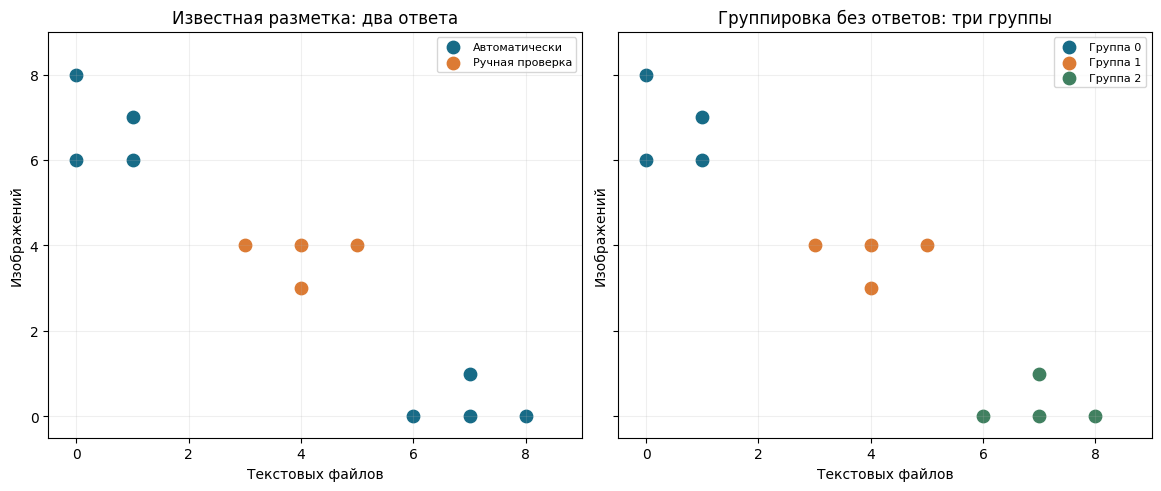

In [9]:
comparison_figure, comparison_axes = plt.subplots(
    1, 2, figsize=(11.5, 4.8), sharex=True, sharey=True,
)
decision_colors = {'Автоматически': '#176B87', 'Ручная проверка': '#DC7B34'}
for label, color in decision_colors.items():
    selected = requests['decision'].eq(label)
    comparison_axes[0].scatter(
        requests.loc[selected, 'text_files'], requests.loc[selected, 'image_files'],
        s=80, color=color, label=label,
    )

group_colors = ['#176B87', '#DC7B34', '#408060']
for group_id, color in enumerate(group_colors):
    selected = clustered_requests['group_id'].eq(group_id)
    comparison_axes[1].scatter(
        clustered_requests.loc[selected, 'text_files'],
        clustered_requests.loc[selected, 'image_files'],
        s=80, color=color, label=f'Группа {group_id}',
    )

for axis in comparison_axes:
    axis.set(xlabel='Текстовых файлов', ylabel='Изображений', xlim=(-0.5, 9), ylim=(-0.5, 9))
    axis.set_xticks(range(0, 10, 2))
    axis.set_yticks(range(0, 10, 2))
    axis.grid(alpha=0.2)
    axis.legend(loc='upper right', fontsize=8)
comparison_axes[0].set_title('Известная разметка: два ответа')
comparison_axes[1].set_title('Группировка без ответов: три группы')
plt.show()

**Разбор выбора и цветов.**

- `plt.subplots(1, 2, ...)` создаёт одну строку из двух областей. Возвращённые рисунок и коллекция областей распаковываются в два имени. `figsize` задаёт размер, `sharex=True`, `sharey=True` согласуют шкалы двух областей.
- `decision_colors = {...}` — словарь: текст класса является ключом, строковый код цвета — значением. `.items()` возвращает пары. Цикл `for label, color in ...:` распаковывает пару и повторяет строки с отступом для каждого класса.
- `.eq(label)` создаёт маску строк текущего класса. `.loc[selected, 'text_files']` и аналогичный выбор изображений возвращают координаты одних и тех же объектов.
- `.scatter(x, y, ...)` рисует отдельные точки. `s=80` задаёт площадь маркеров, `color` — цвет, `label` — подпись для легенды. Коды вида `'#176B87'` являются текстовыми значениями цвета.
- `group_colors` — список трёх цветов. В `enumerate(group_colors)` одновременно выдаются номер, начиная с 0, и элемент. Они попадают в `group_id`, `color` и используются для выбора соответствующей группы.
- В `f'Группа {group_id}'` префикс `f` включает подстановку значения в фигурных скобках. Эта строка служит подписью; она не присваивает группе делового смысла.

**Разбор оформления.**

- `comparison_axes[0]` выбирает левую область, `[1]` — правую. Последний цикл `for axis in comparison_axes:` применяет одинаковое оформление к обеим.
- `.set(...)` задаёт подписи и границы. Кортежи `xlim`, `ylim` содержат нижнюю и верхнюю границы. `.set_xticks(...)`, `.set_yticks(...)` задают деления.
- `range(0, 10, 2)` создаёт целую последовательность от 0 до 8 с шагом 2; правая граница 10 не включается. Это параметры размещения подписей осей.
- `.grid(alpha=0.2)` добавляет полупрозрачную сетку, `.legend(...)` показывает подписи в правом верхнем углу шрифтом размера 8. `.set_title(...)` назначает заголовок конкретной области.
- `plt.show()` выводит рисунок целиком. На этапе этого показа модель группировки больше не обучается и не получает метки из левой картинки.

Заявки с решением «Автоматически» расположены в двух разных группах по составу файлов. Это показывает, почему кластер и известный целевой класс не следует считать одним понятием.

### 3.3. Интерпретация после группировки

Полученную группу можно изучить и дать ей содержательное описание: например, «много текста», «много изображений», «смешанный состав». Это отдельное действие человека после группировки.

В учебном наборе известная разметка специально сохранена для сравнения. Её присоединение к уже готовому результату не меняет то, что фактическое обучение выполнялось без этого столбца.

Этот блок присоединяет известное решение к уже полученным группам только для просмотра. Он выводит состав каждой группы и затем перечисляет заявки с их двумя разными обозначениями: номером группы и решением специалиста.

In [10]:
cluster_review = clustered_requests.merge(
    requests[['request_id', 'decision']],
    on='request_id', validate='one_to_one',
)
group_members = cluster_review.groupby('group_id')['request_id'].agg(list)
display(group_members)
display(cluster_review[['request_id', 'group_id', 'decision']].sort_values(['group_id', 'request_id']))

group_id
0    [R005, R006, R007, R008]
1    [R009, R010, R011, R012]
2    [R001, R002, R003, R004]
Name: request_id, dtype: object

,request_id,group_id,decision
4,R005,0,Автоматически
5,R006,0,Автоматически
6,R007,0,Автоматически
7,R008,0,Автоматически
8,R009,1,Ручная проверка
9,R010,1,Ручная проверка
10,R011,1,Ручная проверка
11,R012,1,Ручная проверка
0,R001,2,Автоматически
1,R002,2,Автоматически


**Разбор кода.**

- `.merge(...)` соединяет результат группировки и два выбранных поля исходной таблицы. `on='request_id'` задаёт ключ соответствия заявок, `validate='one_to_one'` требует не более одной строки с ключом с каждой стороны.
- По умолчанию это соединение по совпавшим ключам. Здесь в обеих таблицах одни и те же двенадцать идентификаторов, поэтому все заявки сохраняются.
- `.groupby('group_id')` собирает записи одной группы вместе. Последующее `['request_id']` оставляет поле идентификаторов, `.agg(list)` превращает их в список для каждой группы.
- `list` передан как действие, без скобок. Применять его к очередной группе будет Pandas. Результат `group_members` — Series, где индекс обозначает номер группы.
- `display(...)` показывает состав групп. Во втором вызове список полей выбирает нужные три столбца, `.sort_values([...])` упорядочивает сначала по группе, затем по идентификатору.
- Код не содержит `.fit` или `.fit_predict`: присоединение разметки происходит после обучения и служит объяснению уже полученного разбиения.

Технический номер группы и бизнес-решение хранятся отдельными полями. Автоматически превратить один в другое только по совпадению отдельных примеров оснований нет.

<a id="reinforcement"></a>
## 4. Обучение с подкреплением: действия и последствия

### 4.1. Агент и среда

В этом разделе агент доставляет посылку через несколько комнат. Он знает текущее состояние и выбирает дверь A или B. Среда сообщает новое состояние, награду и признак завершения попытки.

| Понятие | Значение в примере |
|---|---|
| Агент | программа, выбирающая следующую дверь |
| Среда | правила перехода между комнатами и выдачи награды |
| Состояние | «Вход», «Развилка» или «У выхода» |
| Действие | выбор двери A или B |
| Награда | числовая обратная связь после выбранного действия |
| Политика | правило выбора действия по текущему состоянию |
| Эпизод | одна попытка от входа до доставки или тупика |

Переход в следующую комнату даёт награду −1, доставка — +10, попадание в тупик — −5. Это **выбранные условия учебной задачи**, задающие цель агенту. Они не являются названиями правильных действий в заранее размеченных строках.

Агент должен учитывать последующие последствия. Например, промежуточный переход имеет отрицательную награду за шаг, но может вести к доставке. Цель определяется результатом всей попытки, а не только немедленным сигналом.

Следующий блок описывает небольшую среду: для каждой пары «состояние — дверь» задан переход, награда и завершение. Функция шага возвращает последствия выбранного действия. Обучающий код дальше будет получать опыт через эту функцию.

In [11]:
state_names = ['Вход', 'Развилка', 'У выхода']
action_names = ['A', 'B']
transitions = {
    ('Вход', 'A'): ('Развилка', -1, False),
    ('Вход', 'B'): ('Тупик', -5, True),
    ('Развилка', 'A'): ('Тупик', -5, True),
    ('Развилка', 'B'): ('У выхода', -1, False),
    ('У выхода', 'A'): ('Доставка', 10, True),
    ('У выхода', 'B'): ('Тупик', -5, True),
}

def environment_step(state, action):
    return transitions[(state, action)]

print('Состояния для выбора действия:', state_names)
print('Доступные действия:', action_names)

Состояния для выбора действия: ['Вход', 'Развилка', 'У выхода']
Доступные действия: ['A', 'B']


**Разбор кода.**

- `state_names`, `action_names` — списки текстовых имён. Квадратные скобки создают список, запятые разделяют элементы. Только три состояния требуют следующего действия; доставка и тупик завершают эпизод.
- `transitions = {...}` создаёт словарь. Его ключ `('Вход', 'A')` — кортеж из состояния и действия. Один ключ описывает их пару, а не только состояние.
- Значение после двоеточия тоже кортеж: новое состояние, награда, завершение. Знак `-` перед числом делает награду отрицательной. `True` означает завершение, `False` — возможность продолжить.
- В `def environment_step(state, action):` определяется функция с двумя параметрами. Строка с отступом принадлежит её телу. Функция начинает работать с конкретными значениями только при вызове.
- `transitions[(state, action)]` собирает один ключ-кортеж и ищет его в словаре. Квадратные скобки обращаются к словарю, внутренние круглые скобки объединяют два значения ключа.
- `return` возвращает найденную тройку вызывающему коду. Сам вызов не изменяет внешнюю переменную состояния: новое состояние нужно принять и использовать далее.
- `print(...)` показывает списки. Один знак `=` в определениях сохранял значения, а текст в кавычках задавал имена и подписи.

Таблица переходов — описание учебного мира. Функция обучения не читает её для составления готового маршрута: она пробует действия, вызывает `environment_step` и сохраняет полученные последствия.

Этот блок выполняет одно выбранное действие на входе и отдельно выводит каждый возвращённый результат. Он показывает минимальное взаимодействие агента и среды; обучения по этому шагу пока не происходит.

In [12]:
start_state = 'Вход'
chosen_action = 'A'
next_state, reward, done = environment_step(start_state, chosen_action)

print('До действия:', start_state)
print('Выбранная дверь:', chosen_action)
print('После действия:', next_state)
print('Награда за шаг:', reward)
print('Эпизод завершён:', done)

До действия: Вход
Выбранная дверь: A
После действия: Развилка
Награда за шаг: -1
Эпизод завершён: False


**Разбор кода.**

- Два первых присваивания задают текстовые значения состояния и действия. Это демонстрационный выбор, а не результат обучения.
- `environment_step(start_state, chosen_action)` вызывает ранее определённую функцию. Значения передаются в порядке её параметров: состояние, действие.
- `next_state, reward, done = ...` распаковывает возвращённый кортеж по трём именам. Их порядок соответствует порядку в таблице переходов.
- Переменная `reward` хранит число, `done` — логическое значение. Отрицательная награда промежуточного шага не равна сообщению «вся попытка неудачна»: эпизод может продолжиться.
- Каждый `print(...)` выводит подпись и текущее значение. Результат `False` означает, что после двери A во «Входе» агент находится на развилке и может действовать дальше.

Среда сообщает последствия выбранного действия. Она не возвращает отдельную строку с меткой «какую дверь следовало выбрать» для обучения классификатора.

### 4.2. Что агент хранит между попытками

Для каждого состояния и действия агент будет хранить **оценку последующих наград**. Начальные нули означают отсутствие опыта, а не доказанное отсутствие пользы действия. Отдельно сохраняются накопленные результаты и число наблюдений каждой пары.

Учебный способ обновления использует завершённые эпизоды: для каждого выполненного действия берутся награды от его шага до конца попытки. Повторный опыт уточняет оценку пары. Это учебный табличный вариант управления методом Монте-Карло: оценки обновляются по полученным полным эпизодам.

В этой среде путь короткий и все переходы определены однозначно. Состояния перечислены заранее; таблицы подходят для такого маленького мира. Они не являются универсальным устройством агента для произвольной сложной среды.

Следующий блок создаёт три таблицы с одинаковыми состояниями и действиями: текущие оценки, накопленные результаты и число наблюдений. Все значения пока нулевые. Таблица оценок показывается до первого обновления, чтобы отделить начальные значения от полученных из опыта.

In [13]:
estimates = pd.DataFrame(0.0, index=state_names, columns=action_names)
return_totals = estimates.copy()
visit_counts = pd.DataFrame(0, index=state_names, columns=action_names)
display(estimates)

,A,B
Вход,0.0,0.0
Развилка,0.0,0.0
У выхода,0.0,0.0


**Разбор кода.**

- `pd.DataFrame(0.0, index=..., columns=...)` создаёт таблицу, заполненную одним значением. `index` задаёт подписи строк-состояний, `columns` — подписи столбцов-действий.
- `0.0` записано дробным числом, поэтому оценки могут принимать дробные значения после уточнения. `0` в таблице посещений — целое количество.
- `estimates.copy()` создаёт независимую таблицу накопленных результатов. Без явного копирования простое второе имя для того же объекта не отделяло бы его данные.
- Имена `estimates`, `return_totals`, `visit_counts` означают оценки, накопленные результаты и количества наблюдений. Один знак `=` сохраняет каждый объект под своим именем.
- `display(estimates)` показывает таблицу. Позже `.loc[состояние, действие]` будет выбирать одну её ячейку по подписям, а не по порядковым номерам.

В таблице пока нет освоенного предпочтения. Чтобы получить опыт, агенту нужен способ выбирать действия даже при одинаковых начальных оценках.

### 4.3. Исследование и использование опыта

**Исследование** означает пробу действий, которые могут уточнить представление о среде. **Использование опыта** — выбор действия с наилучшей текущей оценкой. Если всегда использовать только первоначальную догадку, полезные действия могут так и остаться неиспробованными.

В примере настройка исследования определяет долю случайных проб. При использовании оценок одинаково лучшие действия также выбираются случайно, чтобы порядок столбцов не становился единственным основанием выбора.

Этот блок определяет функцию выбора двери. Иногда она берёт пробное действие, в остальных случаях выбирает среди действий с лучшей текущей оценкой. Отдельный генератор случайных чисел используется для демонстрационного выбора до обучения.

In [14]:
def choose_action(state, value_table, rng, exploration_rate):
    if rng.random() < exploration_rate:
        return str(rng.choice(action_names))
    state_values = value_table.loc[state]
    best_actions = state_values.index[state_values.eq(state_values.max())].tolist()
    return str(rng.choice(best_actions))

example_rng = np.random.default_rng(7)
print('Пробное действие:', choose_action('Вход', estimates, example_rng, exploration_rate=0.25))

Пробное действие: B


**Разбор кода.**

- `def choose_action(...):` создаёт функцию с четырьмя параметрами: состояние, таблица оценок, генератор и настройка исследования. Строки с отступом принадлежат телу функции.
- `rng.random()` возвращает псевдослучайное дробное число от 0 включительно до 1 не включительно. Оператор `<` сравнивает его с `exploration_rate`; при `0.25` примерно четверть таких проверок ведёт к случайной пробе.
- `if ...:` выполняет вложенную строку при истинном условии. Первый `return` сразу завершает вызов, поэтому следующие строки выполняются только при выборе использования опыта. Отдельный `else` для этого не требуется.
- `rng.choice(action_names)` выбирает один элемент списка действий. Внешний `str(...)` переводит возвращённое значение в обычную строку Python для дальнейшего использования.
- `value_table.loc[state]` выбирает строку оценок текущего состояния как Series. Её индекс содержит имена действий A и B, значения — их оценки.
- `.max()` находит наибольшее значение строки. `.eq(...)` создаёт маску действий с этим значением. `state_values.index[маска]` выбирает подходящие имена, `.tolist()` превращает их в список.
- Последний `rng.choice(best_actions)` выбирает одно из одинаково лучших действий. Если лучшее действие одно, будет выбрано оно.
- `np.random.default_rng(7)` создаёт генератор с фиксированным начальным значением для воспроизводимости демонстрации. `print(...)` показывает один вызов функции; `exploration_rate=...` передаёт настройку по имени.

При начальных нулях оба действия одинаково оценены, но это не знание об их равной полезности. Выбор позволяет получить первое наблюдение.

Следующий блок собирает целую попытку: начинает со входа, выбирает дверь, получает последствия и продолжает до завершения. Каждый шаг записывается в историю. Для просмотра выполняется один демонстрационный эпизод с начальными оценками.

In [15]:
def run_episode(value_table, rng, exploration_rate):
    state = 'Вход'
    history = []
    for step_number in range(1, 6):
        action = choose_action(state, value_table, rng, exploration_rate)
        next_state, reward, done = environment_step(state, action)
        history.append({
            'step': step_number, 'state': state, 'action': action,
            'reward': reward, 'next_state': next_state, 'done': done,
        })
        state = next_state
        if done:
            break
    return history

example_history = run_episode(estimates, example_rng, exploration_rate=0.25)
display(pd.DataFrame(example_history))

,step,state,action,reward,next_state,done
0,1,Вход,B,-5,Тупик,True


**Разбор кода.**

- `run_episode(...)` — функция одной попытки. Она получает текущие оценки, генератор и настройку выбора. `state = 'Вход'` каждый раз задаёт одно начальное состояние, `history = []` создаёт новый пустой список шагов.
- `for step_number in range(1, 6):` разрешает не более пяти шагов. `range` выдаёт числа 1–5, не включая 6. В данной среде любой эпизод заканчивается не позже третьего шага; предел также делает продолжительность вызова явной.
- `choose_action(...)` выбирает действие по текущему состоянию. `environment_step(...)` возвращает последствия, которые распаковываются в три имени.
- `.append({...})` добавляет в список один словарь шага. Ключи `step`, `state`, `action`, `reward`, `next_state`, `done` означают номер, исходное состояние, действие, награду, новое состояние и завершение.
- `state = next_state` передаёт новое состояние следующему проходу цикла. История уже содержит исходное состояние шага, записанное до этого присваивания.
- `if done:` проверяет логический признак. `break` немедленно прекращает ближайший цикл, поэтому из «Доставки» или «Тупика» новое действие не запрашивается. Двойной отступ показывает условие внутри цикла.
- `return history` находится после цикла и возвращает список всех сделанных шагов. Эта функция собирает опыт, но сама не изменяет оценки по нему.
- `example_history = ...` сохраняет опыт демонстрационной попытки. `pd.DataFrame(example_history)` превращает список словарей в таблицу, `display(...)` показывает её.

Длина истории зависит от действий: не каждая попытка проходит все комнаты. Награда в каждой строке относится именно к действию этой строки.

### 4.4. Обновление после завершённого эпизода

Для выбранной пары «состояние — действие» учитываются награды, полученные от этого шага до завершения. Так поздняя доставка может повлиять на оценку более раннего решения.

Программа сохраняет накопленные результаты и число наблюдений, затем получает уточнённую оценку. В коде это обычные операции над ячейками таблицы. Оценка относится к будущим наградам в собранном опыте, а не к названию правильного действия и не к уверенности классификатора.

Этот блок определяет обновление по истории одной попытки и применяет его к демонстрационному эпизоду. После вызова показываются уточнённые оценки и количества наблюдений. Неиспытанные пары остаются с нулевым числом наблюдений.

In [16]:
def learn_from_episode(history, value_table, reward_totals, counts):
    for start_index, step in enumerate(history):
        following_rewards = []
        for later_step in history[start_index:]:
            following_rewards.append(later_step['reward'])
        observed_return = sum(following_rewards)
        state = step['state']
        action = step['action']
        reward_totals.loc[state, action] += observed_return
        counts.loc[state, action] += 1
        value_table.loc[state, action] = (
            reward_totals.loc[state, action] / counts.loc[state, action]
        )

learn_from_episode(example_history, estimates, return_totals, visit_counts)
display(estimates)
display(visit_counts)

,A,B
Вход,0.0,-5.0
Развилка,0.0,0.0
У выхода,0.0,0.0


,A,B
Вход,0,1
Развилка,0,0
У выхода,0,0


**Разбор истории.**

- `def learn_from_episode(...)` определяет функцию обновления. Параметры после истории — три изменяемые таблицы: оценки, накопленные результаты, количества наблюдений.
- `enumerate(history)` последовательно возвращает номер элемента с 0 и сам словарь шага. Они распаковываются в `start_index` и `step`. Цикл с отступом обрабатывает каждый выполненный шаг.
- Срез `history[start_index:]` берёт историю от текущего шага до конца. Пропущенная правая граница означает конец списка. Прошедшие до текущего шага награды в этот срез не входят.
- Внутренний цикл берёт словарь `later_step`. Выбор `later_step['reward']` читает его награду, `.append(...)` добавляет её в отдельный список. Встроенная `sum(...)` складывает полученные награды и сохраняет результат в `observed_return`.
- `step['state']`, `step['action']` читают исходную пару текущего шага. Ключи словаря — строки, поэтому записаны в кавычках.

**Разбор обновления таблиц.**

- `.loc[state, action]` выбирает одну ячейку по имени состояния и действия. Оператор `+=` добавляет значение к уже сохранённому и записывает результат обратно. Накопленный результат пополняется наблюдением, количество — единицей.
- Оператор `/` делит накопленный результат этой пары на число её наблюдений. Полученное значение присваивается ячейке `value_table`. Деление выполняется после увеличения счётчика, поэтому у обновляемой пары он уже не нулевой.
- Скобки вокруг многострочного выражения продолжают одну инструкцию присваивания. Они не создают новый объект эпизода.
- Функция меняет переданные таблицы через `.loc`; отдельного `return` у неё нет, поэтому возвращаемое значение — `None`. Вызывать её нужно ради обновления объектов, а не присваивать её результат в `estimates`.
- Вызов `learn_from_episode(...)` использует демонстрационную историю. Два `display(...)` показывают фактическое изменение: один — оценок, другой — числа наблюдений.

Это обновление опирается на полученный опыт. В него не передаётся таблица с правильными дверями. Даже неудачная попытка даёт сведения о выбранных действиях.

### 4.5. Последовательность учебных попыток

Обучение чередует две операции: сбор нового эпизода с текущим правилом выбора и обновление оценок по полученному опыту. С изменением оценок меняется выбор в следующих попытках.

Настройка исследования остаётся включённой во время обучения. Поэтому даже после освоения полезного пути иногда будут происходить пробные неудачные действия. Награда отдельной учебной попытки не обязана постоянно увеличиваться.

Следующий блок сбрасывает результат отдельной демонстрации и проводит двести учебных эпизодов с одинаковыми начальными условиями среды. После каждого эпизода агент обновляет оценки. В журнал записываются номер попытки, её награда, завершение доставкой и число шагов.

In [17]:
estimates.loc[:, :] = 0.0
return_totals.loc[:, :] = 0.0
visit_counts.loc[:, :] = 0

training_rng = np.random.default_rng(42)
training_rows = []
for episode_number in range(1, 201):
    history = run_episode(estimates, training_rng, exploration_rate=0.25)
    learn_from_episode(history, estimates, return_totals, visit_counts)
    episode_trace = pd.DataFrame(history)
    training_rows.append({
        'episode': episode_number,
        'reward': episode_trace['reward'].sum(),
        'delivered': history[-1]['next_state'] == 'Доставка',
        'steps': len(history),
    })

training_history = pd.DataFrame(training_rows)
display(training_history.head(12))
print('Учебных эпизодов:', len(training_history))

,episode,reward,delivered,steps
0,1,-5,False,1
1,2,-6,False,2
2,3,-5,False,1
3,4,-5,False,1
4,5,-5,False,1
5,6,-5,False,1
6,7,-5,False,1
7,8,-5,False,1
8,9,-5,False,1
9,10,-5,False,1


Учебных эпизодов: 200


**Разбор подготовки.**

- `.loc[:, :]` выбирает все строки и все столбцы. Присваивание 0 или 0.0 сбрасывает три таблицы после одиночного демонстрационного обновления. У нового учебного запуска нет скрытого преимущества от этой демонстрации.
- `np.random.default_rng(42)` создаёт отдельный генератор для всей последовательности обучения. Он инициализируется один раз **до цикла**, поэтому последующие эпизоды получают новую случайность, а не повтор одного начального выбора.
- `training_rows = []` создаёт пустой список будущих строк журнала. `range(1, 201)` выдаёт номера от 1 до 200 включительно.

**Разбор каждого эпизода.**

- `run_episode(...)` получает текущие оценки. Именованный аргумент `exploration_rate=0.25` сохраняет исследовательские пробы. Функция возвращает фактически выполненную историю.
- `learn_from_episode(...)` сразу обновляет три таблицы по этой истории. На следующем проходе `run_episode` уже прочитает изменённые оценки.
- `pd.DataFrame(history)` превращает текущую историю в таблицу шагов. Выбор `['reward'].sum()` складывает награды именно этого эпизода и даёт один результат для журнала.
- `history[-1]` выбирает последний словарь истории. Последующее `['next_state']` читает его конечное состояние. Оператор `== 'Доставка'` возвращает логический признак успешного завершения, а не изменяет состояние.
- `len(history)` — число сделанных шагов. `.append({...})` добавляет одну строку журнала как словарь из четырёх полей. Отступы внутри цикла показывают, что все эти действия повторяются для каждого эпизода.
- После окончания цикла `pd.DataFrame(training_rows)` собирает общий журнал. `.head(12)` берёт начало для показа через `display(...)`, `print(...)` выводит полное число строк.

Журнал позволяет связать наблюдаемые результаты с конкретными попытками. Он не является набором готовых правильных действий: строки появились после взаимодействий агента со средой.

Этот блок показывает накопленные оценки и число наблюдений после обучения. Затем для каждого состояния выбирается действие с наибольшей текущей оценкой. Полученная Series — явное представление освоенного правила выбора без исследовательских проб.

In [18]:
display(estimates.round(2))
display(visit_counts)
learned_policy = estimates.idxmax(axis=1).rename('Выбранная дверь')
display(learned_policy)

,A,B
Вход,4.17,-5.00
Развилка,-5.00,6.98
У выхода,10.00,-5.00


,A,B
Вход,166,34
Развилка,25,141
У выхода,122,19


Вход        A
Развилка    B
У выхода    A
Name: Выбранная дверь, dtype: object

**Разбор кода.**

- `estimates.round(2)` возвращает представление значений с округлением до двух знаков после точки. Результат передаётся в `display(...)`; исходные оценки не переназначаются и сохраняют свою точность.
- `display(visit_counts)` показывает, сколько раз каждая пара участвовала в обновлении. Счётчик помогает отличать оценку с опытом от начального нуля.
- `.idxmax(axis=1)` ищет наибольшее значение **по столбцам каждой строки** и возвращает имя соответствующего столбца. Поэтому результатом становятся действия A или B, а не сами числовые оценки.
- При точном равенстве максимумов `idxmax` выбирает первое встреченное имя. В функции выбора действий для взаимодействий равенство обрабатывалось случайным выбором; это различие нужно учитывать при чтении таблицы политики.
- `.rename('Выбранная дверь')` задаёт имя полученной Series. Индексом остаются состояния, значениями — действия. Переменная `learned_policy` сохраняет результат для просмотра.

Оценки не являются процентами уверенности или метками классов. Политика извлекает из накопленного опыта предпочтение действия в каждом состоянии.

### 4.6. Применение после обучения

Теперь выполняется отдельный проход с выключенным исследованием. На каждом шаге выбирается действие с лучшей оценкой, а сами оценки не обновляются. Это позволяет отделить применение освоенного правила от дальнейшего обучения.

В маленькой детерминированной среде проверка показывает конкретный путь и награду. Она не доказывает пригодность агента для другой среды, других стартовых условий или реальной доставки.

Следующий блок запускает агента после обучения без исследовательских действий и выводит весь получившийся маршрут. Проверка в конце подтверждает доставку в этой учебной среде. По шагам видно, какие решения были приняты и когда пришла награда.

In [19]:
evaluation_rng = np.random.default_rng(123)
evaluation_history = run_episode(estimates, evaluation_rng, exploration_rate=0.0)
evaluation_trace = pd.DataFrame(evaluation_history)
evaluation_reward = evaluation_trace['reward'].sum()

display(evaluation_trace)
print('Завершение:', evaluation_history[-1]['next_state'])
print('Награда за эпизод:', evaluation_reward)
assert evaluation_history[-1]['next_state'] == 'Доставка', 'Учебная доставка не выполнена'

,step,state,action,reward,next_state,done
0,1,Вход,A,-1,Развилка,False
1,2,Развилка,B,-1,У выхода,False
2,3,У выхода,A,10,Доставка,True


Завершение: Доставка
Награда за эпизод: 8


**Разбор кода.**

- `np.random.default_rng(123)` создаёт отдельный генератор для проверки. Он нужен интерфейсу выбора действий, в том числе на случай одинаковых лучших оценок.
- `run_episode(..., exploration_rate=0.0)` выключает ветвь исследовательского выбора. Функция использует уже накопленную таблицу `estimates`. При равных лучших оценках по-прежнему выбиралось бы одно из них.
- `pd.DataFrame(evaluation_history)` создаёт таблицу проверки. `.sum()` в столбце `reward` получает награду всей этой попытки; результат сохраняется в `evaluation_reward`.
- `display(...)` показывает последовательность шагов. Выражение `evaluation_history[-1]['next_state']` последовательно выбирает последний словарь и его конечное состояние; `print(...)` выводит его вместе с подписью.
- `assert условие, 'сообщение'` останавливает выполнение, если условие ложно. Оператор `==` сравнивает конечное состояние с доставкой. Эта проверка фиксирует ожидаемый результат учебного примера, а не передаёт правильные действия в обучение.
- Здесь нет вызова `learn_from_episode`, поэтому таблицы накопленного опыта в этой ячейке не изменяются. Поведение определяется результатом предыдущих эпизодов.

Освоенный маршрут проходит через три решения и заканчивается доставкой. Награда последнего шага отлична от промежуточных сигналов; обновление по эпизодам позволяет учитывать её и для ранних действий.

Последний кодовый блок сопоставляет награды учебных эпизодов с результатом прохода после обучения без исследования. Он показывает, почему отдельные провалы во время исследовательских проб совместимы с освоенным успешным выбором в этой среде.

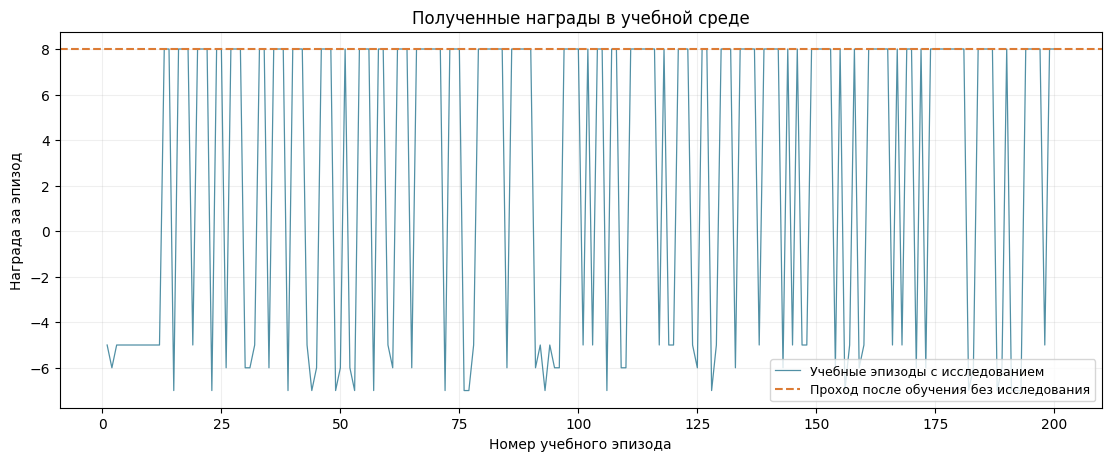

In [20]:
reward_figure, reward_axis = plt.subplots(figsize=(11, 4.5))
reward_axis.plot(
    training_history['episode'], training_history['reward'],
    linewidth=0.9, alpha=0.75, color='#176B87', label='Учебные эпизоды с исследованием',
)
reward_axis.axhline(
    evaluation_reward, color='#DC7B34', linestyle='--',
    label='Проход после обучения без исследования',
)
reward_axis.set(
    title='Полученные награды в учебной среде',
    xlabel='Номер учебного эпизода', ylabel='Награда за эпизод',
)
reward_axis.grid(alpha=0.2)
reward_axis.legend(loc='lower right', fontsize=9)
plt.show()

**Разбор кода.**

- `plt.subplots(figsize=(11, 4.5))` создаёт рисунок и одну область. Два результата распаковываются в `reward_figure`, `reward_axis`; размеры переданы кортежем.
- `.plot(...)` получает из `training_history` столбцы номера и награды. Они задают горизонтальные и вертикальные значения в одинаковом порядке строк.
- `linewidth=0.9` задаёт толщину линии, `alpha=0.75` — прозрачность, `color` — цвет. `label` сохраняет подпись для легенды. Эти настройки не изменяют накопленные награды.
- `.axhline(evaluation_reward, ...)` рисует горизонтальную линию на уровне результата отдельного проверочного эпизода. `linestyle='--'` делает её штриховой.
- `.set(...)` задаёт заголовок и подписи осей. `.grid(alpha=0.2)` добавляет полупрозрачную сетку. `.legend(loc='lower right', fontsize=9)` показывает подписи справа внизу заданным размером шрифта.
- `plt.show()` выводит рисунок. К этому моменту обучение завершено; построение графика не передаёт агенту новых наград и не меняет правило выбора.

Резкие снижения линии связаны с конкретными полученными эпизодами, включая продолжающиеся исследовательские действия. Пунктир относится к одному проходу после обучения. Эти данные описывают разные режимы работы агента.

<a id="comparison"></a>
## 5. Сопоставление трёх способов

### 5.1. Что фактически использовалось и сохранилось

| Пример | Что было передано при обучении | Сохранённый результат | Что происходит при применении |
|---|---|---|---|
| Решение и время по заявке | входные поля и отдельный целевой столбец | обученные `classifier` и `regressor` | модель получает новые входы и возвращает предсказание |
| Группы заявок | только два входных поля | разбиение переданной партии и номера групп | готовые группы изучаются и интерпретируются |
| Доставка через двери | истории состояний, действий и наград | таблица оценок и правило выбора по ней | агент выбирает действие и получает следующий отклик среды |

У группировки в этом файле результат относится к обработанной партии. У классификатора и регрессора отдельно показано предсказание для новых заявок. У агента получение нового отклика среды ещё не равно обновлению: для обучения требуется отдельный вызов, который использует опыт.

### 5.2. Один сервис может сочетать эти способы

Для журнала заявок можно сначала изучить состав обращений группировкой. После содержательной разметки специалистами отдельная модель может учиться возвращать известные решения для новых заявок. Если задача переходит к последовательному управлению — например, выбору исполнителя с учётом меняющейся очереди, — понадобятся состояния, доступные действия и обратная связь о последствиях, характерные для постановки с подкреплением.

Выбор определяется целью и доступным сигналом. Исторические правильные ответы позволяют поставить задачу с учителем; исследование структуры без таких ответов — задачу без учителя; улучшение действий через их последствия — задачу с подкреплением. Название библиотеки или тип используемой модели сами по себе этот выбор не определяют.